# Занятие 8

In [1]:
# Запустите этот код, чтобы проверить, 
# что у вас корректные версии инструментов.

import sys

try:
    import pandas as pd
    print(f"✅ pandas установлен! Версия: {pd.__version__}")
except ImportError:
    print("pandas не установлен.")
    %pip install pandas==3.1.0

try:
    import numpy as np
    print(f"✅ numpy установлен! Версия: {np.__version__}")
except ImportError:
    print("numpy не установлен.")
    %pip install numpy==2.5.4

def _version_check(current: int, required: int) -> bool:
    return current >= required

if not _version_check(
    current=sys.version_info.minor,
    required=13,
):
    sys.exit(f"Версия python {sys.version_info.minor}")

if not _version_check(
    current=int(pd.__version__[0]),
    required=3,
):
    sys.exit(f"Версия pandas {pd.__version__[0]}")

print("Все ок ✅")

✅ pandas установлен! Версия: 3.1.0
✅ numpy установлен! Версия: 2.5.4
Все ок ✅


In [2]:
import pandas as pd
df = pd.read_csv("world-happiness-report.csv")
df.head(10)

,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.724,7.370,0.451,50.80,0.718,0.168,0.882,0.518,0.258
1,Afghanistan,2009,4.402,7.540,0.552,51.20,0.679,0.190,0.850,0.584,0.237
2,Afghanistan,2010,4.758,7.647,0.539,51.60,0.600,0.121,0.707,0.618,0.275
3,Afghanistan,2011,3.832,7.620,0.521,51.92,0.496,0.162,0.731,0.611,0.267
4,Afghanistan,2012,3.783,7.705,0.521,52.24,0.531,0.236,0.776,0.710,0.268
5,Afghanistan,2013,3.572,7.725,0.484,52.56,0.578,0.061,0.823,0.621,0.273
6,Afghanistan,2014,3.131,7.718,0.526,52.88,0.509,0.104,0.871,0.532,0.375
7,Afghanistan,2015,3.983,7.702,0.529,53.20,0.389,0.080,0.881,0.554,0.339
8,Afghanistan,2016,4.220,7.697,0.559,53.00,0.523,0.042,0.793,0.565,0.348
9,Afghanistan,2017,2.662,7.697,0.491,52.80,0.427,-0.121,0.954,0.496,0.371


- `Country name` - название страны

- `year` – год

- `Life Ladder` - лестница жизни Лестница жизни — это субъективная шкала, на которой респонденты
оценивают свое счастье. Им предлагают представить лестницу с 10 ступенями:

0 — это худшая возможная жизнь, какую можно себе представить 10 — это лучшая возможная жизнь
Респонденты выбирают число от 0 до 10, которое соответствует их оценке текущего уровня жизни.

- `Social support` - социальная поддержка Измеряется на основе вопроса: «Есть ли у вас кто-то, на
кого можно положиться в трудные времена?». Показывает уровень доверия и прочность социальных связей
в обществе.

- `Healthy life expectancy at birth` - ожидаемая продолжительность жизни Показывает, сколько лет в
среднем человек может прожить в хорошем здоровье. Является индикатором уровня медицины, качества
жизни и экологии.

- `Freedom to make life choices` - свобода принимать жизненные решения Основан на вопросе: «Довольны
ли вы свободой выбора в вашей жизни?». Оценивает степень личной свободы и возможности самостоятельно
принимать решения.

- Generosity - Щедрость Измеряется по уровню благотворительности: «Жертвовали ли вы деньги на
благотворительность в последний месяц?», показывает уровень альтруизма и готовность помогать другим.

- `Perceptions of corruption` - Восприятие коррупции Отражает восприятие коррупции в правительстве и
бизнесе, чем выше коррупция, тем ниже уровень доверия граждан к власти.

- `Positive affect` - Частота позитивных эмоций

- `Negative affect` - Частота негативных эмоций

In [3]:
# 1. Найдите размер дата-фрейма, а также информацию о типах данных каждого столбца.

df.info()
df.shape
# len(df.columns)

print(f"Колонок {df.shape[1]}, строк {df.shape[0]}")


<class 'pandas.DataFrame'>
RangeIndex: 1949 entries, 0 to 1948
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country name                      1949 non-null   str    
 1   year                              1949 non-null   int64  
 2   Life Ladder                       1949 non-null   float64
 3   Log GDP per capita                1913 non-null   float64
 4   Social support                    1936 non-null   float64
 5   Healthy life expectancy at birth  1894 non-null   float64
 6   Freedom to make life choices      1917 non-null   float64
 7   Generosity                        1860 non-null   float64
 8   Perceptions of corruption         1839 non-null   float64
 9   Positive affect                   1927 non-null   float64
 10  Negative affect                   1933 non-null   float64
dtypes: float64(9), int64(1), str(1)
memory usage: 167.6 KB
Колонок 11, строк 1949


In [4]:
# 2. Найдите количество стран, представленных в дата-фрейме и для каждой страны, посчитайте количество записей.
# В ответе укажите общее количество стран.

countries = df["Country name"].value_counts()
countries



Country name
Argentina     15
Bangladesh    15
Bolivia       15
Brazil        15
Cambodia      15
              ..
Cuba           1
Guyana         1
Maldives       1
Oman           1
Suriname       1
Name: count, Length: 166, dtype: int64

In [5]:
countries = df["Country name"].unique()

f"Количество стран: {len(list(countries))}"

'Количество стран: 166'

In [6]:
# 3. Определите диапазон лет, данные за которые представлены в дата-фрейме.

df["year"].min()
df["year"].max()

f"Минимум {df["year"].min()}, максимум {df["year"].max()}"

'Минимум 2005, максимум 2020'

In [7]:
# 4. Найдите столбцы с пропущенными значениями и подсчитайте их количество. 
# Затем в столбце с минимальным количеством пропущенных значений (отличных от 0) — 
# заполните строки средним значением. 
# Для столбца с максимальным количеством пропущенных значений — удалите строки. 

df.isna().sum()

Country name                          0
year                                  0
Life Ladder                           0
Log GDP per capita                   36
Social support                       13
Healthy life expectancy at birth     55
Freedom to make life choices         32
Generosity                           89
Perceptions of corruption           110
Positive affect                      22
Negative affect                      16
dtype: int64

In [8]:
df_isna = df.isna().sum().rename_axis("Название колонки"
                            ).reset_index(name="Кол-во пустых значений"
                                          ).sort_values(by="Кол-во пустых значений")

df_isna = df_isna[df_isna["Кол-во пустых значений"] > 0]
# df_isna.iloc[0]["Название колонки"]
# df_isna.iloc[-1]["Название колонки"]

In [9]:
df_isna.iloc[0]["Название колонки"]

'Social support'

In [10]:
df_isna.iloc[-1]["Название колонки"]

'Perceptions of corruption'

In [11]:
# Затем в столбце с минимальным количеством пропущенных значений (отличных от 0) — 
# заполните строки средним значением. 
# Для столбца с максимальным количеством пропущенных значений — удалите строки. 

df['Social support'] = df['Social support'].fillna(df['Social support'].mean())
df = df.dropna(subset=['Perceptions of corruption'])



In [12]:
df.isna().sum()

Country name                         0
year                                 0
Life Ladder                          0
Log GDP per capita                  35
Social support                       0
Healthy life expectancy at birth    55
Freedom to make life choices        13
Generosity                          74
Perceptions of corruption            0
Positive affect                     10
Negative affect                      6
dtype: int64

In [13]:
# 5. Найдите страны, у которых уровень восприятие коррупции меньше 0.3 
# и при этом социальная поддержка выше 0.9.
# В ответе укажите количество полученных стран.

filtered = df[(df["Perceptions of corruption"] < 0.3) & (df["Social support"] > 0.9)]

In [14]:
len(filtered["Country name"].value_counts())
filtered["Country name"].unique()

<StringArray>
[             'Denmark',              'Finland',          'Netherlands',
          'New Zealand',               'Norway',            'Singapore',
               'Sweden',          'Switzerland', 'United Arab Emirates']
Length: 9, dtype: str

In [15]:
# 6. Выведите топ-5 стран с наибольшим значением позитивных эмоций за 2015 год.
# В ответе укажите страну, находящуюся на 5 месте.

positive_2015_df = df[df["year"] == 2015]
positive_2015_df = positive_2015_df[["Country name", "Positive affect"]]
# positive_2015_df.value_counts("Country name")
positive_2015_df.sort_values(by="Positive affect", ascending=False).head(5)

,Country name,Positive affect
1721,Thailand,0.910
1560,Somalia,0.901
1860,Uruguay,0.893
756,Indonesia,0.876
1888,Venezuela,0.867


In [16]:
#7. Определите год с самым высоким средним значением 
# ВВП на душу населения по всем странам и визуализируйте результаты.
# В ответе укажите год.

df7 = df[["year", "Log GDP per capita"]]
# df7.groupby("year").mean().sort_values("Log GDP per capita", ascending=True)

grouped = df7.groupby("year").mean()
grouped.idxmax()



Log GDP per capita    2005
dtype: int64

<Axes: xlabel='year'>

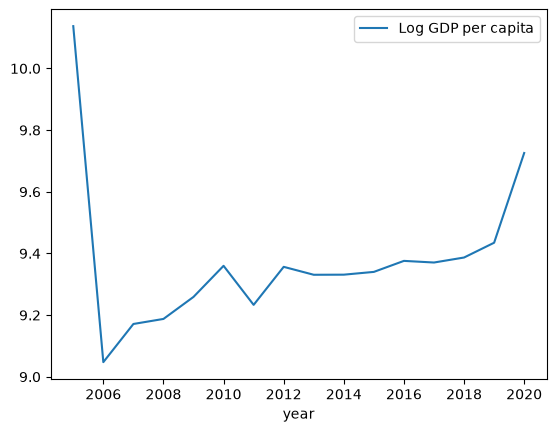

In [17]:
grouped.plot(kind="line")